# Predicting Himalayan Expedition Success
CSC61304 Machine Learning and Intelligent Systems - individual assignment

Name: Kritak Aryal (0382309)

**Question:** before an expedition starts, can we predict if it will reach the summit?

**Models:** Logistic Regression (baseline), Random Forest, XGBoost

**Data:** Himalayan Database, shared by TidyTuesday (22 Sep 2020). Download `expeditions.csv` and `peaks.csv` from
https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-09-22 and keep them in the same folder as this notebook.

# Importing libraires

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")


# EDA

https://www.geeksforgeeks.org/data-analysis/exploratory-data-analysis-in-python/


In [2]:
expeditions = pd.read_csv("expeditions.csv")
peaks = pd.read_csv("peaks.csv")

In [4]:
expeditions.head()

,expedition_id,peak_id,peak_name,year,season,basecamp_date,highpoint_date,termination_date,termination_reason,highpoint_metres,members,member_deaths,hired_staff,hired_staff_deaths,oxygen_used,trekking_agency
0,ANN260101,ANN2,Annapurna II,1960,Spring,1960-03-15,1960-05-17,NaN,Success (main peak),7937.0,10,0,9,0,True,NaN
1,ANN269301,ANN2,Annapurna II,1969,Autumn,1969-09-25,1969-10-22,1969-10-26,Success (main peak),7937.0,10,0,0,0,False,NaN
2,ANN273101,ANN2,Annapurna II,1973,Spring,1973-03-16,1973-05-06,NaN,Success (main peak),7937.0,6,0,8,0,False,NaN
3,ANN278301,ANN2,Annapurna II,1978,Autumn,1978-09-08,1978-10-02,1978-10-05,"Bad weather (storms, high winds)",7000.0,2,0,0,0,False,NaN
4,ANN279301,ANN2,Annapurna II,1979,Autumn,NaN,1979-10-18,1979-10-20,"Bad weather (storms, high winds)",7160.0,3,0,0,0,False,NaN


In [5]:
peaks.head()

,peak_id,peak_name,peak_alternative_name,height_metres,climbing_status,first_ascent_year,first_ascent_country,first_ascent_expedition_id
0,AMAD,Ama Dablam,Amai Dablang,6814,Climbed,1961.0,"New Zealand, USA, UK",AMAD61101
1,AMPG,Amphu Gyabjen,NaN,5630,Climbed,1953.0,UK,AMPG53101
2,ANN1,Annapurna I,NaN,8091,Climbed,1950.0,France,ANN150101
3,ANN2,Annapurna II,NaN,7937,Climbed,1960.0,"UK, Nepal",ANN260101
4,ANN3,Annapurna III,NaN,7555,Climbed,1961.0,India,ANN361101


In [6]:
expeditions.shape

(10364, 16)

In [9]:
peaks.shape

(468, 8)

In [10]:
expeditions.info()

<class 'pandas.DataFrame'>
RangeIndex: 10364 entries, 0 to 10363
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   expedition_id       10364 non-null  str    
 1   peak_id             10364 non-null  str    
 2   peak_name           10363 non-null  str    
 3   year                10364 non-null  int64  
 4   season              10364 non-null  str    
 5   basecamp_date       9269 non-null   str    
 6   highpoint_date      9714 non-null   str    
 7   termination_date    7984 non-null   str    
 8   termination_reason  10364 non-null  str    
 9   highpoint_metres    9950 non-null   float64
 10  members             10364 non-null  int64  
 11  member_deaths       10364 non-null  int64  
 12  hired_staff         10364 non-null  int64  
 13  hired_staff_deaths  10364 non-null  int64  
 14  oxygen_used         10364 non-null  bool   
 15  trekking_agency     8654 non-null   str    
dtypes: bool(1), flo

In [11]:
peaks.info()

<class 'pandas.DataFrame'>
RangeIndex: 468 entries, 0 to 467
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   peak_id                     468 non-null    str    
 1   peak_name                   468 non-null    str    
 2   peak_alternative_name       245 non-null    str    
 3   height_metres               468 non-null    int64  
 4   climbing_status             468 non-null    str    
 5   first_ascent_year           336 non-null    float64
 6   first_ascent_country        336 non-null    str    
 7   first_ascent_expedition_id  333 non-null    str    
dtypes: float64(1), int64(1), str(6)
memory usage: 29.4 KB


In [15]:
expeditions.describe().T

,count,mean,std,min,25%,50%,75%,max
year,10364.0,2001.156310,14.710054,1905.0,1994.0,2005.0,2012.0,2019.0
highpoint_metres,9950.0,7408.923819,1012.628339,3500.0,6700.0,7300.0,8188.0,8850.0
members,10364.0,5.953300,5.428004,0.0,2.0,5.0,8.0,99.0
member_deaths,10364.0,0.076032,0.377665,0.0,0.0,0.0,0.0,10.0
hired_staff,10364.0,2.776920,5.081277,0.0,0.0,1.0,3.0,99.0
hired_staff_deaths,10364.0,0.030683,0.284747,0.0,0.0,0.0,0.0,11.0


In [16]:
peaks.describe().T

,count,mean,std,min,25%,50%,75%,max
height_metres,468.0,6656.636752,571.912791,5407.0,6235.75,6559.5,6911.0,8850.0
first_ascent_year,336.0,1979.077381,100.205460,201.0,1963.00,1982.0,2008.0,2019.0


In [17]:
expedition_columns = expeditions.columns.tolist()

In [18]:
peaks_columns = peaks.columns.tolist()

In [19]:
expedition_columns

['expedition_id',
 'peak_id',
 'peak_name',
 'year',
 'season',
 'basecamp_date',
 'highpoint_date',
 'termination_date',
 'termination_reason',
 'highpoint_metres',
 'members',
 'member_deaths',
 'hired_staff',
 'hired_staff_deaths',
 'oxygen_used',
 'trekking_agency']

In [20]:
peaks_columns

['peak_id',
 'peak_name',
 'peak_alternative_name',
 'height_metres',
 'climbing_status',
 'first_ascent_year',
 'first_ascent_country',
 'first_ascent_expedition_id']

In [21]:
expeditions.isnull().sum()

expedition_id            0
peak_id                  0
peak_name                1
year                     0
season                   0
basecamp_date         1095
highpoint_date         650
termination_date      2380
termination_reason       0
highpoint_metres       414
members                  0
member_deaths            0
hired_staff              0
hired_staff_deaths       0
oxygen_used              0
trekking_agency       1710
dtype: int64

In [22]:
peaks.isnull().sum()

peak_id                         0
peak_name                       0
peak_alternative_name         223
height_metres                   0
climbing_status                 0
first_ascent_year             132
first_ascent_country          132
first_ascent_expedition_id    135
dtype: int64

# Joining the peak height from peaks to expeditions

In [24]:
peaks_small = peaks[["peak_id", "height_metres"]]
df = expeditions.merge(peaks_small, on="peak_id", how="left")
df.shape

(10364, 17)

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10364 entries, 0 to 10363
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   expedition_id       10364 non-null  str    
 1   peak_id             10364 non-null  str    
 2   peak_name           10363 non-null  str    
 3   year                10364 non-null  int64  
 4   season              10364 non-null  str    
 5   basecamp_date       9269 non-null   str    
 6   highpoint_date      9714 non-null   str    
 7   termination_date    7984 non-null   str    
 8   termination_reason  10364 non-null  str    
 9   highpoint_metres    9950 non-null   float64
 10  members             10364 non-null  int64  
 11  member_deaths       10364 non-null  int64  
 12  hired_staff         10364 non-null  int64  
 13  hired_staff_deaths  10364 non-null  int64  
 14  oxygen_used         10364 non-null  bool   
 15  trekking_agency     8654 non-null   str    
 16  height_metres  

In [26]:
df["termination_reason"].value_counts()

termination_reason
Success (main peak)                                                             5581
Bad weather (storms, high winds)                                                1307
Bad conditions (deep snow, avalanching, falling ice, or rock)                   1097
Illness, AMS, exhaustion, or frostbite                                           458
Route technically too difficult, lack of experience, strength, or motivation     438
Other                                                                            320
Accident (death or serious injury)                                               299
Did not attempt climb                                                            233
Lack (or loss) of supplies or equipment                                          220
Success (subpeak)                                                                126
Unknown                                                                           96
Lack of time                                  

In [27]:
# these rows are not a real attempt (or the summit is unclear), so remove them
remove = ["Did not attempt climb", "Attempt rumoured", "Unknown", "Did not reach base camp", "Success (subpeak)"]
df = df[~df["termination_reason"].isin(remove)]

# season Unknown is only 2 rows
df = df[df["season"] != "Unknown"]

df["success"] = df["termination_reason"].apply(lambda x: 1 if x in ["Success (main peak)", "Success (claimed)"] else 0)
print(df.shape)
df["success"].value_counts()

(9832, 18)


success
1    5600
0    4232
Name: count, dtype: int64

# Features I will use
Only things known **before** the expedition starts. I do not use `highpoint_metres`, `termination_date`, `termination_reason`, `member_deaths` because they are only known after the expedition (that would be cheating / data leakage).

In [28]:
df["has_agency"] = df["trekking_agency"].notna().astype(int)   # 1 if a trekking agency is written
df["oxygen_used"] = df["oxygen_used"].astype(int)

features = ["year", "season", "members", "hired_staff", "oxygen_used", "has_agency", "height_metres"]
data = df[features + ["success"]]
data.head()

,year,season,members,hired_staff,oxygen_used,has_agency,height_metres,success
0,1960,Spring,10,9,1,0,7937.0,1
1,1969,Autumn,10,0,0,0,7937.0,1
2,1973,Spring,6,8,0,0,7937.0,1
3,1978,Autumn,2,0,0,0,7937.0,0
4,1979,Autumn,3,0,0,0,7937.0,0


In [29]:
data.isnull().sum()

year             0
season           0
members          0
hired_staff      0
oxygen_used      0
has_agency       0
height_metres    1
success          0
dtype: int64

# EDA After combining and feature selections

success rate: 0.57


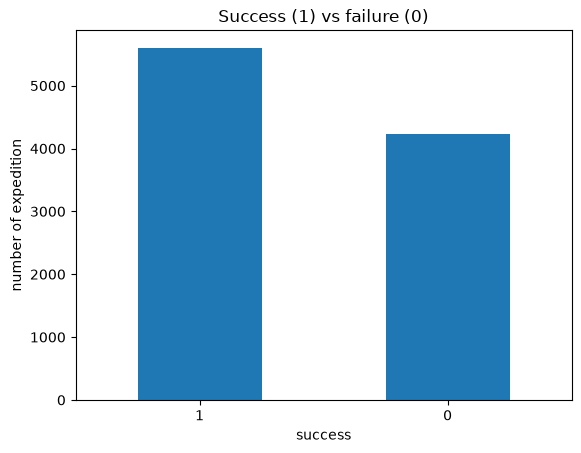

In [44]:
print("success rate:", data["success"].mean().round(3))
data["success"].value_counts().plot(kind="bar")
plt.title("Success (1) vs failure (0)")
plt.xticks(rotation=0)
plt.ylabel("number of expedition")
plt.show()

**Classes:** ~5600 success vs ~4232 failure (57% / 43%). Fairly balanced, so no need for resampling. But a model that always says "success" is already right 57-59% of the time, so my accuracy must be compared with that number.

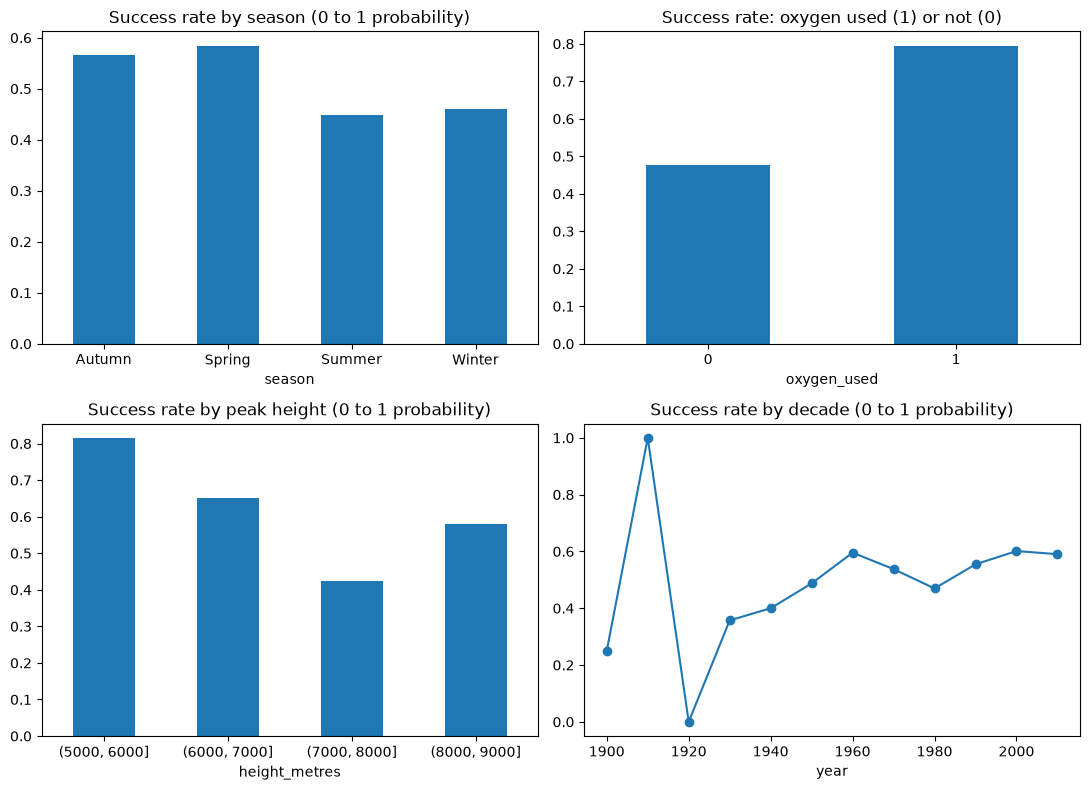

In [38]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))

data.groupby("season")["success"].mean().plot(kind="bar", ax=ax[0, 0], rot=0)
ax[0, 0].set_title("Success rate by season (0 to 1 probability)")

data.groupby("oxygen_used")["success"].mean().plot(kind="bar", ax=ax[0, 1], rot=0)
ax[0, 1].set_title("Success rate: oxygen used (1) or not (0)")

data.groupby(pd.cut(data["height_metres"], [5000, 6000, 7000, 8000, 9000]))["success"].mean().plot(kind="bar", ax=ax[1, 0], rot=0)
ax[1, 0].set_title("Success rate by peak height (0 to 1 probability)")

data.groupby((data["year"] // 10) * 10)["success"].mean().plot(marker="o", ax=ax[1, 1])
ax[1, 1].set_title("Success rate by decade (0 to 1 probability)")

plt.tight_layout()
plt.savefig("eda_success_rates.png")
plt.show()

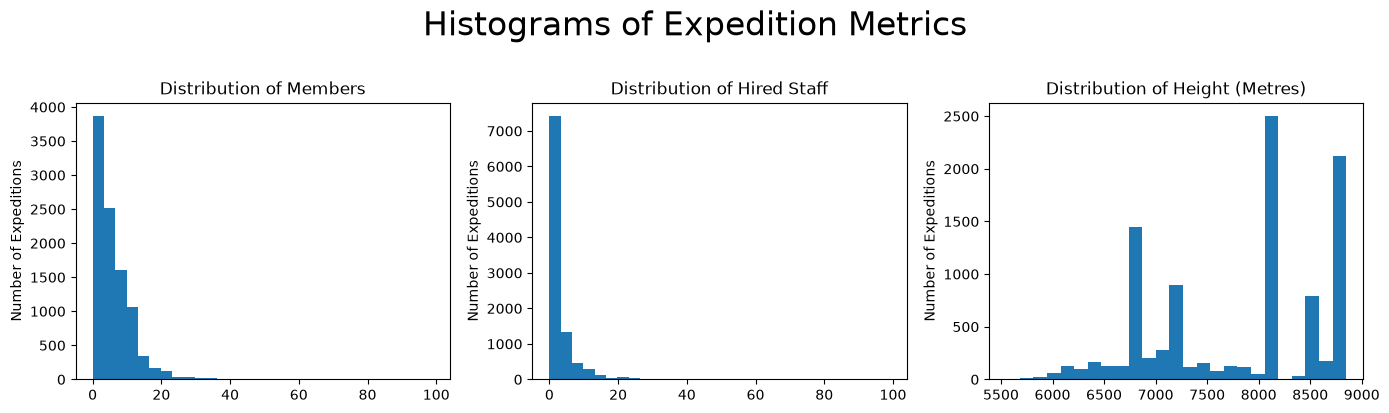

In [42]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

# Overall figure title
fig.suptitle("Histograms of Expedition Metrics", fontsize=24, y=1.02)

ax[0].hist(data["members"], bins=30)
ax[0].set_title("Distribution of Members")
ax[0].set_ylabel("Number of Expeditions")

ax[1].hist(data["hired_staff"], bins=30)
ax[1].set_title("Distribution of Hired Staff")
ax[1].set_ylabel("Number of Expeditions")

ax[2].hist(data["height_metres"].dropna(), bins=25)
ax[2].set_title("Distribution of Height (Metres)")
ax[2].set_ylabel("Number of Expeditions")

plt.tight_layout()
plt.show()

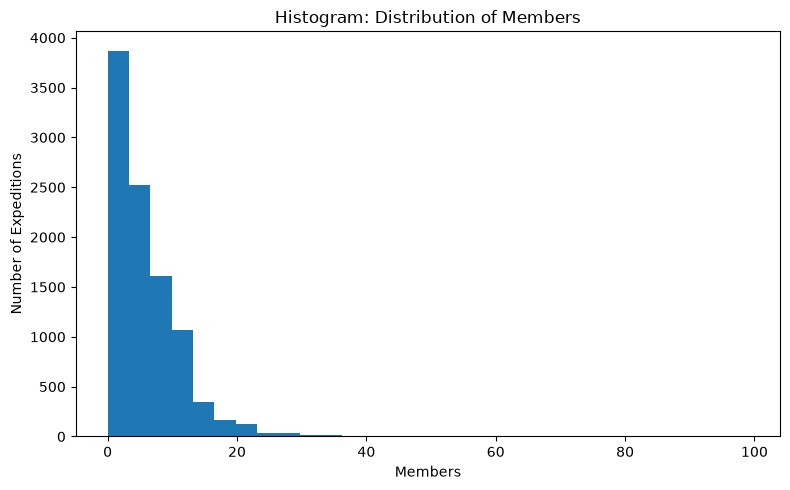

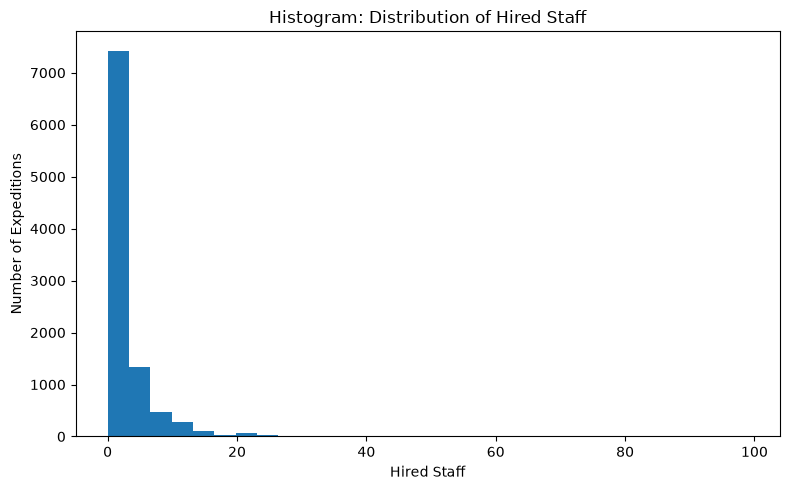

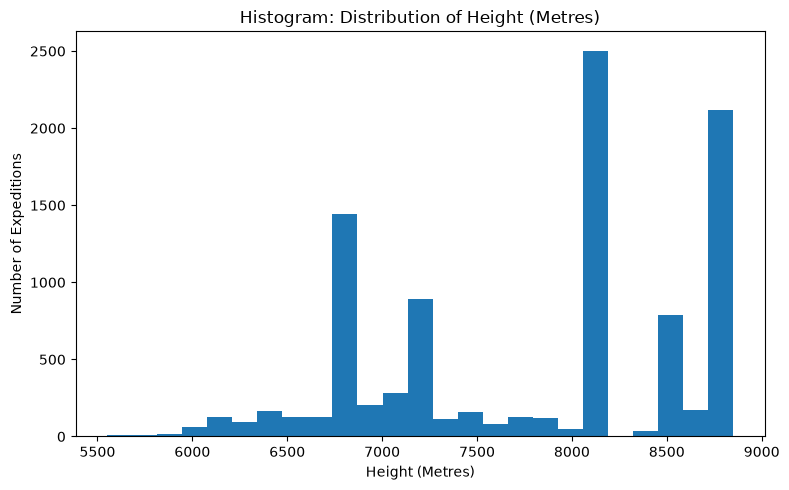

In [41]:
# 1. Members histogram
plt.figure(figsize=(8, 5))
plt.hist(data["members"], bins=30)
plt.title("Histogram: Distribution of Members")
plt.xlabel("Members")
plt.ylabel("Number of Expeditions")
plt.tight_layout()
plt.show()

# 2. Hired staff histogram
plt.figure(figsize=(8, 5))
plt.hist(data["hired_staff"], bins=30)
plt.title("Histogram: Distribution of Hired Staff")
plt.xlabel("Hired Staff")
plt.ylabel("Number of Expeditions")
plt.tight_layout()
plt.show()

# 3. Height histogram
plt.figure(figsize=(8, 5))
plt.hist(data["height_metres"].dropna(), bins=25)
plt.title("Histogram: Distribution of Height (Metres)")
plt.xlabel("Height (Metres)")
plt.ylabel("Number of Expeditions")
plt.tight_layout()
plt.show()

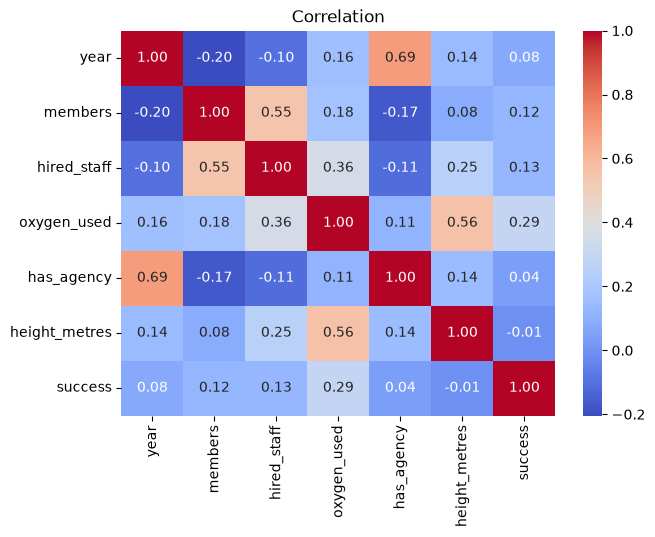

In [43]:
plt.figure(figsize=(7, 5))
sns.heatmap(data.drop(columns="season").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation")
plt.show()

the use of oxygen has highest correlation to success of clime, hence, highest at 0.29 followed by hired_staff and members of 0.13, 0.12

In [45]:
# how many expeditions are in each group? (a success rate means little if the group is tiny)
print(data["season"].value_counts())
print()
print(pd.cut(data["height_metres"], [5000, 6000, 7000, 8000, 9000]).value_counts().sort_index())
print()
print(data["year"].floordiv(10).mul(10).value_counts().sort_index())

season
Autumn    4754
Spring    4683
Winter     306
Summer      89
Name: count, dtype: int64

height_metres
(5000, 6000]      43
(6000, 7000]    2341
(7000, 8000]    1809
(8000, 9000]    5638
Name: count, dtype: int64

year
1900       4
1910       1
1920       8
1930      28
1940      10
1950     119
1960     136
1970     331
1980    1122
1990    1668
2000    3093
2010    3312
Name: count, dtype: int64


not much expeditions during summer and winters, almost all are during autumn and spring, at similar proportions
not much expedition of height of below 6,000 meters. only 43
innitial years had less expeditions, but as decades go by, more and more expeditions were recorded

In [46]:
# height and oxygen together: success rate and number of expeditions
height_group = pd.cut(data["height_metres"], [5000, 6000, 7000, 8000, 9000])
print(data.groupby([height_group, "oxygen_used"])["success"].agg(["mean", "size"]).round(3))

                            mean  size
height_metres oxygen_used             
(5000, 6000]  0            0.795    39
              1            1.000     4
(6000, 7000]  0            0.652  2298
              1            0.558    43
(7000, 8000]  0            0.415  1721
              1            0.591    88
(8000, 9000]  0            0.370  2891
              1            0.803  2747


In [47]:
# has_agency is it real information or just "recent records"?
print(data.groupby((data["year"] // 10) * 10)["has_agency"].mean().round(2))

year
1900    0.00
1910    0.00
1920    0.00
1930    0.00
1940    0.00
1950    0.00
1960    0.00
1970    0.03
1980    0.41
1990    0.93
2000    0.98
2010    0.98
Name: has_agency, dtype: float64


**Reading the checks above:** season Summer has only 89 expeditions and Winter 306, so their success rates are not reliable. Before 1950 there are fewer than 30 expeditions per decade. Above 8000 m, success without oxygen is 37% but with oxygen 80%, so height and oxygen must be read together. has_agency is 0% before 1970 and 98% after 2000, which means it follows the year more than it follows success.

# Preprocessing
1. one hot encode `season`
2. split by time (train = up to 2009, test = 2010 onwards). A random split would let the model see future expeditions while training, so I split by year.
3. fill missing height with the **train** median (so nothing from test leaks in)
4. scale the numbers (needed for Logistic Regression only, trees do not care)

In [48]:
data = pd.get_dummies(data, columns=["season"], drop_first=True)
data.head()

,year,members,hired_staff,oxygen_used,has_agency,height_metres,success,season_Spring,season_Summer,season_Winter
0,1960,10,9,1,0,7937.0,1,True,False,False
1,1969,10,0,0,0,7937.0,1,False,False,False
2,1973,6,8,0,0,7937.0,1,True,False,False
3,1978,2,0,0,0,7937.0,0,False,False,False
4,1979,3,0,0,0,7937.0,0,False,False,False


In [49]:
train = data[data["year"] <= 2009]
test = data[data["year"] >= 2010]

X_train = train.drop(columns="success")
y_train = train["success"]
X_test = test.drop(columns="success")
y_test = test["success"]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("success rate train:", y_train.mean().round(3))
print("success rate test:", y_test.mean().round(3))

Train: (6520, 9) | Test: (3312, 9)
success rate train: 0.559
success rate test: 0.59


In [50]:
train_median = X_train["height_metres"].median()
X_train["height_metres"] = X_train["height_metres"].fillna(train_median)
X_test["height_metres"] = X_test["height_metres"].fillna(train_median)
print("Missing left:", X_train.isnull().sum().sum() + X_test.isnull().sum().sum())

Missing left: 0


In [53]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# training 3 models, default settings

In [54]:
print("logistic regression")
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)


logistic regression


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [57]:
print("random forest")

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

random forest


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [59]:
print("xg boost")
xgb = XGBClassifier(n_estimators=200, random_state=42)
xgb.fit(X_train, y_train)

xg boost


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [63]:
def show_scores(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    print(f"{name} (threshold={threshold})")
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"F1:        {f1_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_true, y_prob):.4f}")
    print()


threshold = 0.5  # Changing this to see the difference

show_scores("Logistic Regression", y_test, lr.predict_proba(X_test_scaled)[:, 1], threshold)
show_scores("Random Forest", y_test, rf.predict_proba(X_test)[:, 1], threshold)
show_scores("XGBoost", y_test, xgb.predict_proba(X_test)[:, 1], threshold)

Logistic Regression (threshold=0.5)
Accuracy:  0.7065
Precision: 0.6954
Recall:    0.8946
F1:        0.7826
ROC-AUC:   0.7727

Random Forest (threshold=0.5)
Accuracy:  0.7065
Precision: 0.7174
Recall:    0.8297
F1:        0.7694
ROC-AUC:   0.7453

XGBoost (threshold=0.5)
Accuracy:  0.7126
Precision: 0.7260
Recall:    0.8240
F1:        0.7719
ROC-AUC:   0.7617



In [72]:
from sklearn.metrics import precision_score


def show_precision(name, y_true, y_prob, threshold=0.60):
    y_pred = (y_prob >= threshold).astype(int)
    print(f"{name} (threshold={threshold}) - Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")


threshold = 0.90

show_precision("Logistic Regression", y_test, lr.predict_proba(X_test_scaled)[:, 1], threshold)
show_precision("Random Forest", y_test, rf.predict_proba(X_test)[:, 1], threshold)
show_precision("XGBoost", y_test, xgb.predict_proba(X_test)[:, 1], threshold)

Logistic Regression (threshold=0.9) - Precision: 0.7750
Random Forest (threshold=0.9) - Precision: 0.8443
XGBoost (threshold=0.9) - Precision: 0.8686


In [73]:
import numpy as np
from sklearn.metrics import precision_score


def show_precision(name, y_true, y_prob, threshold=0.60):
    y_pred = (y_prob >= threshold).astype(int)
    print(f"{name} (threshold={threshold:.2f}) - Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")


thresholds = np.arange(0.35, 0.90 + 1e-9, 0.05)

for t in thresholds:
    t = round(float(t), 2)
    show_precision("Logistic Regression", y_test, lr.predict_proba(X_test_scaled)[:, 1], t)
    show_precision("Random Forest", y_test, rf.predict_proba(X_test)[:, 1], t)
    show_precision("XGBoost", y_test, xgb.predict_proba(X_test)[:, 1], t)
    print()

Logistic Regression (threshold=0.35) - Precision: 0.5981
Random Forest (threshold=0.35) - Precision: 0.6681
XGBoost (threshold=0.35) - Precision: 0.6824

Logistic Regression (threshold=0.40) - Precision: 0.6241
Random Forest (threshold=0.40) - Precision: 0.6782
XGBoost (threshold=0.40) - Precision: 0.6886

Logistic Regression (threshold=0.45) - Precision: 0.6648
Random Forest (threshold=0.45) - Precision: 0.6936
XGBoost (threshold=0.45) - Precision: 0.7088

Logistic Regression (threshold=0.50) - Precision: 0.6954
Random Forest (threshold=0.50) - Precision: 0.7174
XGBoost (threshold=0.50) - Precision: 0.7260

Logistic Regression (threshold=0.55) - Precision: 0.7085
Random Forest (threshold=0.55) - Precision: 0.7252
XGBoost (threshold=0.55) - Precision: 0.7347

Logistic Regression (threshold=0.60) - Precision: 0.7305
Random Forest (threshold=0.60) - Precision: 0.7377
XGBoost (threshold=0.60) - Precision: 0.7434

Logistic Regression (threshold=0.65) - Precision: 0.7713
Random Forest (thre

In [74]:
import numpy as np
from sklearn.metrics import precision_score

thresholds = np.round(np.arange(0.35, 0.90 + 1e-9, 0.05), 2)

probs_by_model = {
    "Logistic Regression": lr.predict_proba(X_test_scaled)[:, 1],
    "Random Forest": rf.predict_proba(X_test)[:, 1],
    "XGBoost": xgb.predict_proba(X_test)[:, 1],
}

precision_curves = {}
for name, y_prob in probs_by_model.items():
    precision_curves[name] = [
        precision_score(y_test, (y_prob >= t).astype(int), zero_division=0)
        for t in thresholds
    ]

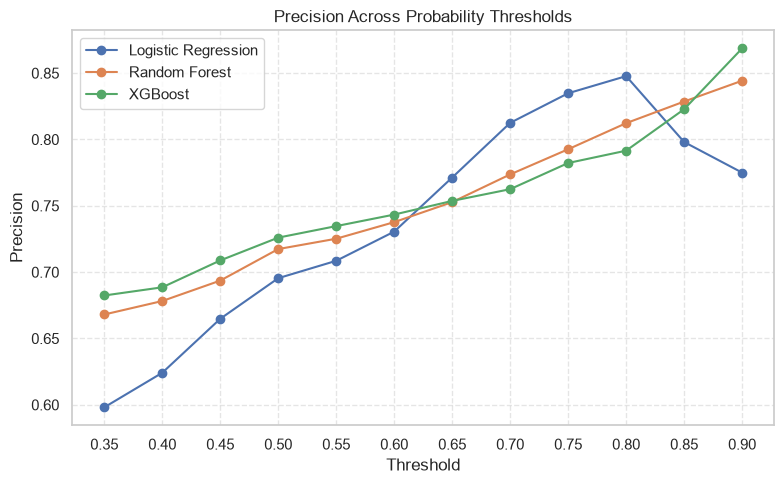

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for name, precisions in precision_curves.items():
    plt.plot(thresholds, precisions, marker="o", label=name)

plt.title("Precision Across Probability Thresholds")
plt.xlabel("Threshold")
plt.ylabel("Precision")
plt.xticks(thresholds)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [76]:
import numpy as np
from sklearn.metrics import precision_score, recall_score

thresholds = np.round(np.arange(0.35, 0.90 + 1e-9, 0.05), 2)
min_precision = 0.78  # Change to whatever minimum precision you want


def pick_threshold(y_true, y_prob, min_prec=0.78):
    valid = []
    for t in thresholds:
        preds = (y_prob >= t).astype(int)
        n_pos = int(preds.sum())
        prec = precision_score(y_true, preds, zero_division=0)
        rec = recall_score(y_true, preds, zero_division=0)
        if prec >= min_prec and n_pos > 0:
            valid.append((t, prec, rec, n_pos))
    # Among thresholds meeting min_prec, pick the one with highest recall (most successes caught)
    return max(valid, key=lambda x: x[2]) if valid else None


models = {
    "Logistic Regression": lr.predict_proba(X_test_scaled)[:, 1],
    "Random Forest": rf.predict_proba(X_test)[:, 1],
    "XGBoost": xgb.predict_proba(X_test)[:, 1],
}

for name, y_prob in models.items():
    choice = pick_threshold(y_test, y_prob, min_precision)
    if choice:
        t, prec, rec, n_pos = choice
        print(f"{name}: threshold={t:.2f} | Precision={prec:.4f} | Recall={rec:.4f} | Predicted 1s={n_pos}")
    else:
        print(f"{name}: no threshold met Precision >= {min_precision}")

Logistic Regression: threshold=0.70 | Precision=0.8125 | Recall=0.6184 | Predicted 1s=1488
Random Forest: threshold=0.75 | Precision=0.7926 | Recall=0.5376 | Predicted 1s=1326
XGBoost: threshold=0.75 | Precision=0.7822 | Recall=0.6174 | Predicted 1s=1543


In [77]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": (
        lr,
        X_train_scaled,
        {"C": [0.01, 0.1, 1, 10], "penalty": ["l2"], "solver": ["lbfgs"]},
    ),
    "Random Forest": (
        rf,
        X_train,
        {"n_estimators": [100, 200], "max_depth": [5, 10, None], "min_samples_split": [2, 5]},
    ),
    "XGBoost": (
        xgb,
        X_train,
        {"n_estimators": [100, 200], "max_depth": [3, 5, 7], "learning_rate": [0.05, 0.1]},
    ),
}

tuned_models = {}

for name, (estimator, X_data, grid) in param_grids.items():
    search = GridSearchCV(
        estimator=estimator,
        param_grid=grid,
        scoring="precision",
        cv=5,
        n_jobs=-1,
    )
    search.fit(X_data, y_train)
    tuned_models[name] = search
    print(f"{name} -> Best CV Precision: {search.best_score_:.4f} | Params: {search.best_params_}")

C:\Users\asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Logistic Regression -> Best CV Precision: 0.6406 | Params: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
Random Forest -> Best CV Precision: 0.5951 | Params: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 200}
XGBoost -> Best CV Precision: 0.5646 | Params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}


In [78]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

test_inputs = {
    "Logistic Regression": X_test_scaled,
    "Random Forest": X_test,
    "XGBoost": X_test,
}

rows = []
for name, search in tuned_models.items():
    best_est = search.best_estimator_
    X_eval = test_inputs[name]
    y_pred = best_est.predict(X_eval)
    y_prob = best_est.predict_proba(X_eval)[:, 1]

    rows.append(
        {
            "Model": name,
            "CV_Precision": round(search.best_score_, 4),
            "Test_Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
            "Test_Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
            "Test_F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
            "Test_ROC_AUC": round(roc_auc_score(y_test, y_prob), 4),
        }
    )

summary_df = pd.DataFrame(rows).sort_values(by="Test_Precision", ascending=False)
display(summary_df)

best_model_name = summary_df.iloc[0]["Model"]
print(f"\nBest Model (by Precision): {best_model_name}")

,Model,CV_Precision,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
1,Random Forest,0.5951,0.7621,0.8307,0.7949,0.8074
2,XGBoost,0.5646,0.7387,0.8517,0.7912,0.8014
0,Logistic Regression,0.6406,0.6954,0.8946,0.7826,0.7727



Best Model (by Precision): Random Forest


In [79]:
for name, search in tuned_models.items():
    print(f"=== All Tested Combinations: {name} ===")
    cv_df = pd.DataFrame(search.cv_results_)
    cols = [c for c in cv_df.columns if c.startswith("param_")] + ["mean_test_score", "rank_test_score"]
    display(cv_df[cols].sort_values(by="rank_test_score").round(4))

=== All Tested Combinations: Logistic Regression ===


,param_C,param_penalty,param_solver,mean_test_score,rank_test_score
3,10.00,l2,lbfgs,0.6406,1
2,1.00,l2,lbfgs,0.6406,1
1,0.10,l2,lbfgs,0.6406,3
0,0.01,l2,lbfgs,0.6335,4


=== All Tested Combinations: Random Forest ===


,param_max_depth,param_min_samples_split,param_n_estimators,mean_test_score,rank_test_score
3,5,5,200,0.5951,1
1,5,2,200,0.5947,2
2,5,5,100,0.5936,3
0,5,2,100,0.5935,4
4,10,2,100,0.5747,5
6,10,5,100,0.5699,6
7,10,5,200,0.5688,7
5,10,2,200,0.5669,8
8,None,2,100,0.5495,9
10,None,5,100,0.5483,10


=== All Tested Combinations: XGBoost ===


,param_learning_rate,param_max_depth,param_n_estimators,mean_test_score,rank_test_score
0,0.05,3,100,0.5646,1
2,0.05,5,100,0.5476,2
6,0.10,3,100,0.5431,3
1,0.05,3,200,0.5398,4
10,0.10,7,100,0.5319,5
8,0.10,5,100,0.5311,6
4,0.05,7,100,0.5307,7
3,0.05,5,200,0.5305,8
11,0.10,7,200,0.5300,9
7,0.10,3,200,0.5290,10


In [80]:
import numpy as np
from sklearn.metrics import precision_score

thresholds = np.round(np.arange(0.35, 0.90 + 1e-9, 0.05), 2)

best_probs = {
    "Logistic Regression": tuned_models["Logistic Regression"].best_estimator_.predict_proba(X_test_scaled)[:, 1],
    "Random Forest": tuned_models["Random Forest"].best_estimator_.predict_proba(X_test)[:, 1],
    "XGBoost": tuned_models["XGBoost"].best_estimator_.predict_proba(X_test)[:, 1],
}

for t in thresholds:
    for name, y_prob in best_probs.items():
        y_pred = (y_prob >= t).astype(int)
        prec = precision_score(y_test, y_pred, zero_division=0)
        print(f"{name} (threshold={t:.2f}) - Precision: {prec:.4f}")
    print()

Logistic Regression (threshold=0.35) - Precision: 0.5981
Random Forest (threshold=0.35) - Precision: 0.6131
XGBoost (threshold=0.35) - Precision: 0.6371

Logistic Regression (threshold=0.40) - Precision: 0.6241
Random Forest (threshold=0.40) - Precision: 0.6240
XGBoost (threshold=0.40) - Precision: 0.6684

Logistic Regression (threshold=0.45) - Precision: 0.6648
Random Forest (threshold=0.45) - Precision: 0.6962
XGBoost (threshold=0.45) - Precision: 0.7134

Logistic Regression (threshold=0.50) - Precision: 0.6954
Random Forest (threshold=0.50) - Precision: 0.7621
XGBoost (threshold=0.50) - Precision: 0.7387

Logistic Regression (threshold=0.55) - Precision: 0.7085
Random Forest (threshold=0.55) - Precision: 0.7895
XGBoost (threshold=0.55) - Precision: 0.7750

Logistic Regression (threshold=0.60) - Precision: 0.7305
Random Forest (threshold=0.60) - Precision: 0.8286
XGBoost (threshold=0.60) - Precision: 0.8016

Logistic Regression (threshold=0.65) - Precision: 0.7713
Random Forest (thre

In [81]:
from sklearn.metrics import confusion_matrix, recall_score

chosen_t = 0.75

for name, y_prob in best_probs.items():
    y_pred = (y_prob >= chosen_t).astype(int)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(
        f"{name} (t={chosen_t:.2f}) -> Precision: {prec:.4f} | "
        f"Recall: {rec:.4f} | FP: {fp} | Predicted 1s: {int(y_pred.sum())}"
    )

Logistic Regression (t=0.75) -> Precision: 0.8348 | Recall: 0.4317 | FP: 167 | Predicted 1s: 1011
Random Forest (t=0.75) -> Precision: 0.8946 | Recall: 0.3949 | FP: 91 | Predicted 1s: 863
XGBoost (t=0.75) -> Precision: 0.8937 | Recall: 0.3698 | FP: 86 | Predicted 1s: 809


In [86]:
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

threshold = 0.75

models_eval = [
    ("Logistic Regression", tuned_models["Logistic Regression"].best_estimator_, X_test_scaled),
    ("Random Forest", tuned_models["Random Forest"].best_estimator_, X_test),
    ("XGBoost", tuned_models["XGBoost"].best_estimator_, X_test),
]

rows = []
for name, model, X_eval in models_eval:
    y_prob = model.predict_proba(X_eval)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)
    _, fp, _, _ = confusion_matrix(y_test, y_pred).ravel()

    rows.append(
        {
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, y_prob),
            "False Positives": int(fp),
            "Predicted 1s": int(y_pred.sum()),
        }
    )

results = pd.DataFrame(rows).round(4)
results["False Positives"] = results["False Positives"].astype(int)
results["Predicted 1s"] = results["Predicted 1s"].astype(int)
display(results)

,Model,Threshold,Precision,Recall,F1,ROC-AUC,False Positives,Predicted 1s
0,Logistic Regression,0.75,0.8348,0.4317,0.5691,0.7727,167,1011
1,Random Forest,0.75,0.8946,0.3949,0.5479,0.8074,91,863
2,XGBoost,0.75,0.8937,0.3698,0.5232,0.8014,86,809


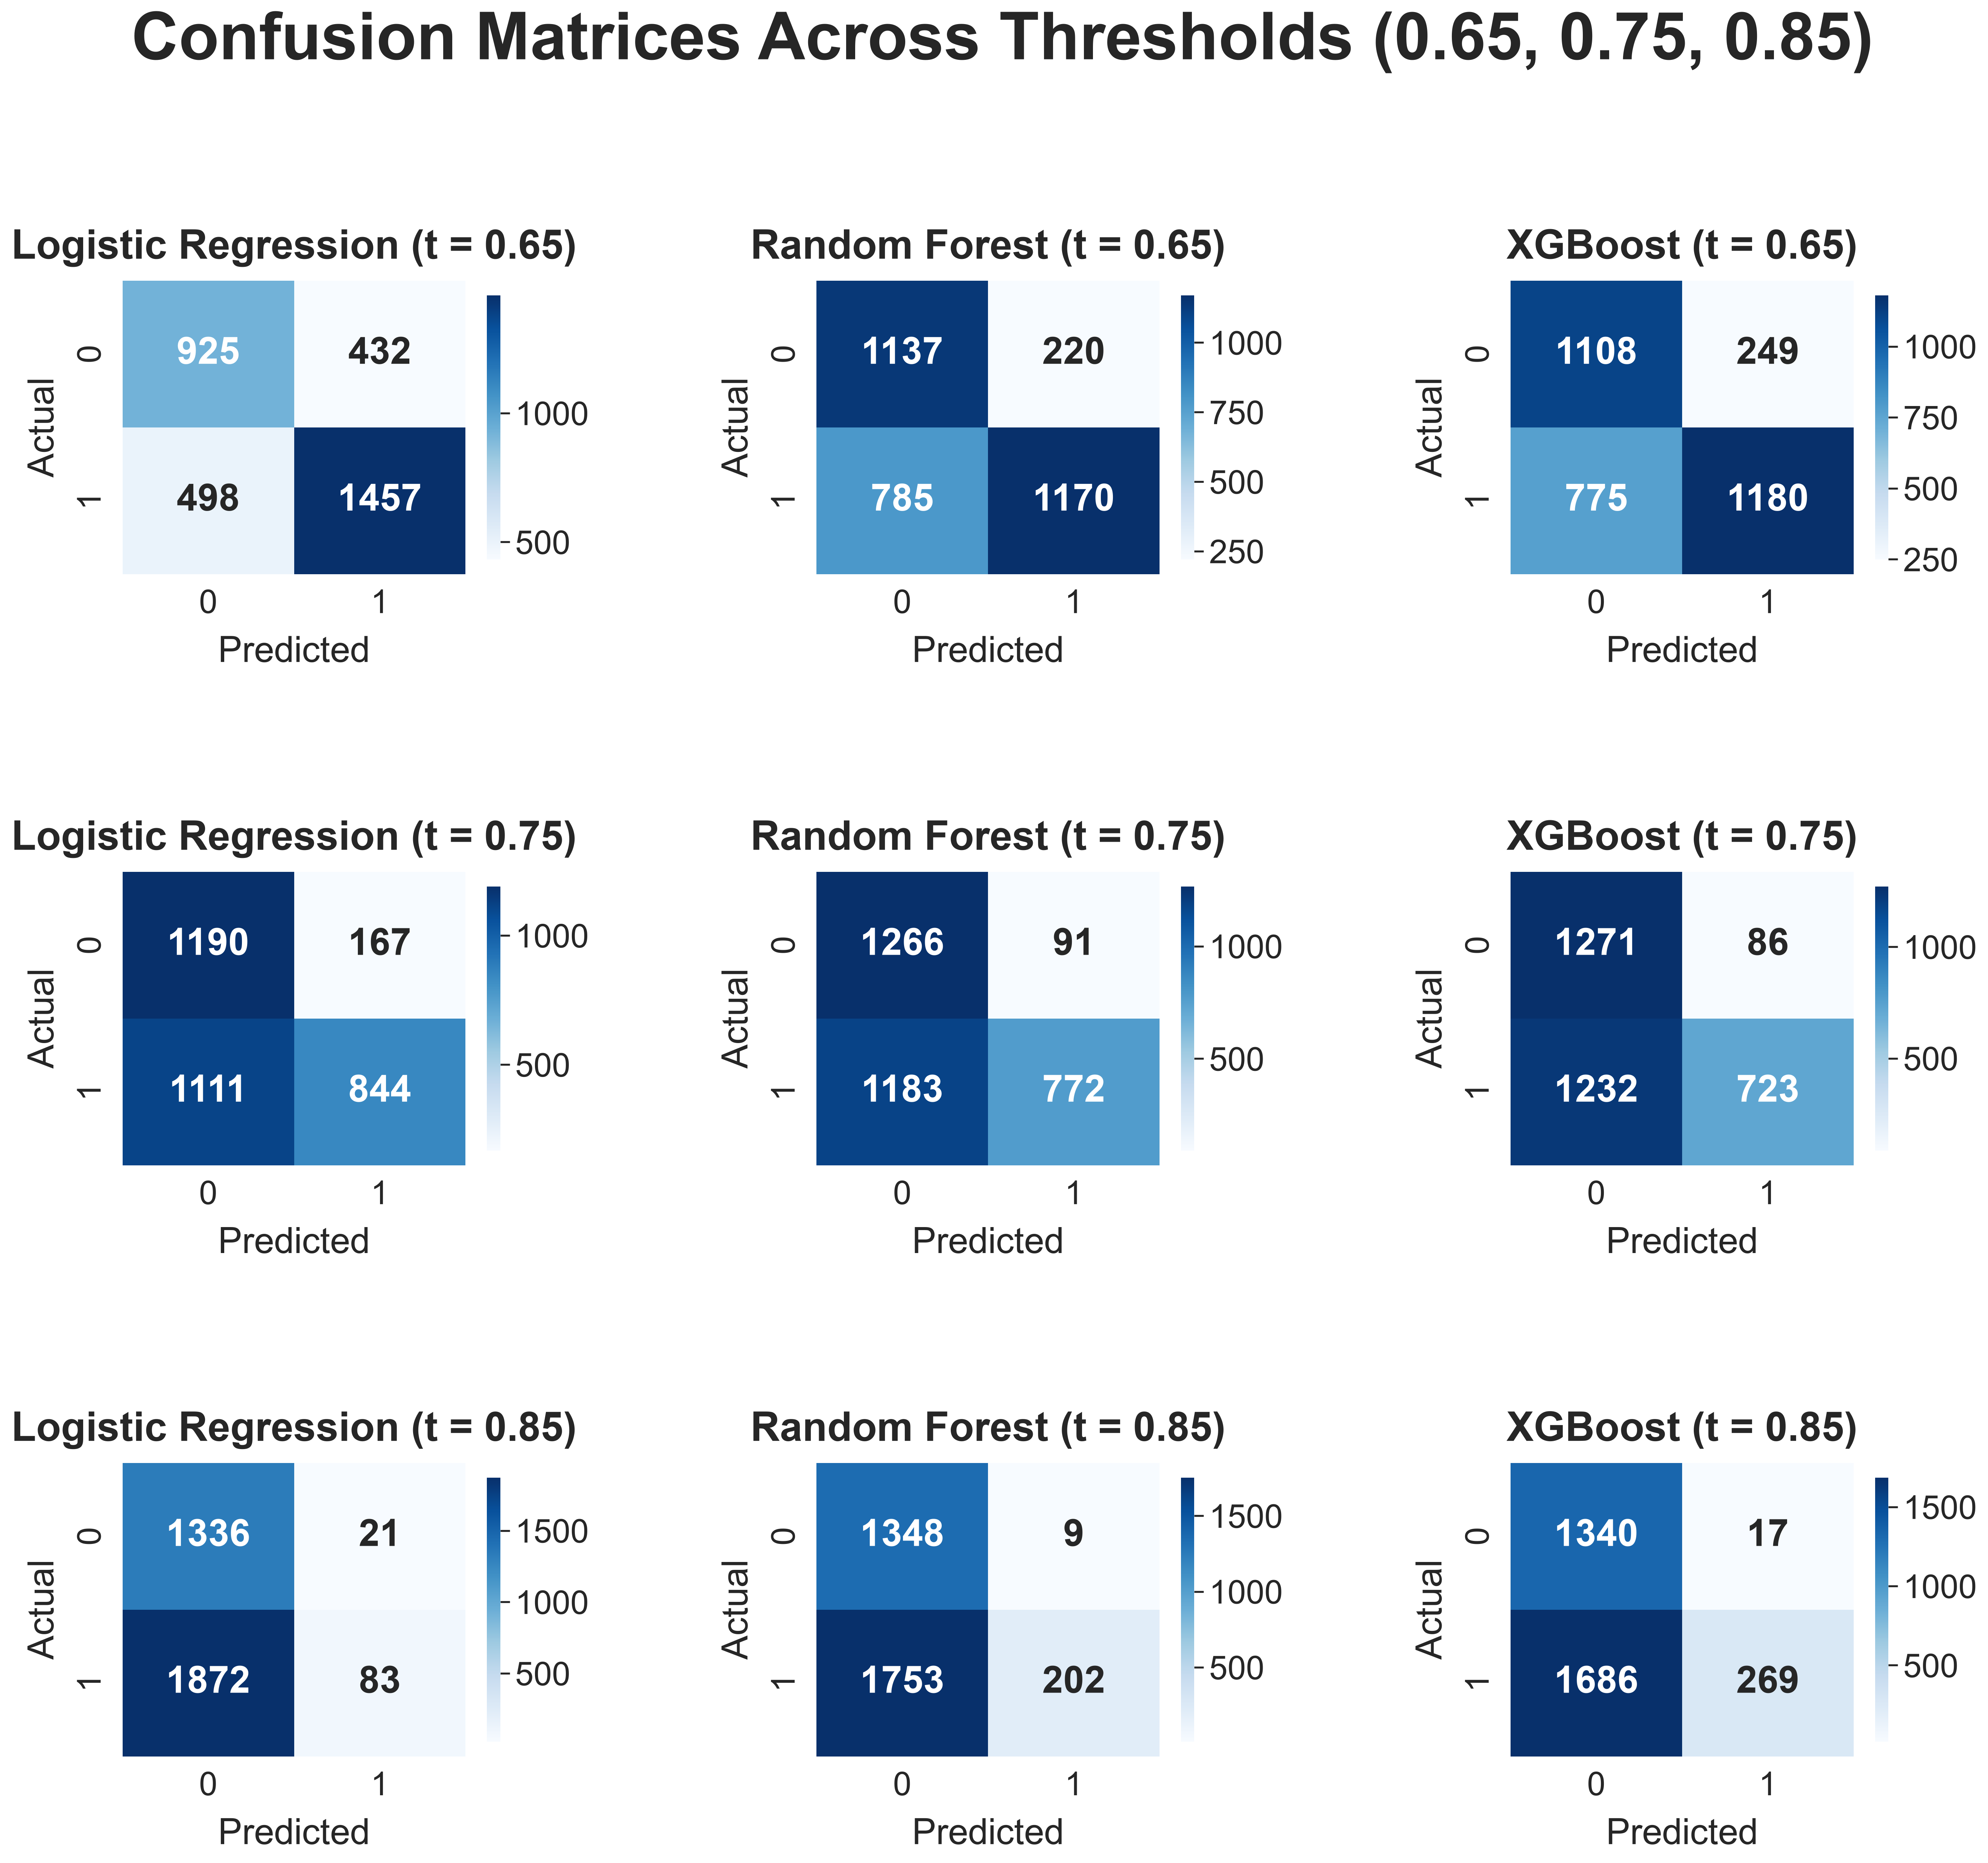

In [101]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

thresholds = [0.65, 0.75, 0.85]

models_eval = [
    ("Logistic Regression", tuned_models["Logistic Regression"].best_estimator_, X_test_scaled),
    ("Random Forest", tuned_models["Random Forest"].best_estimator_, X_test),
    ("XGBoost", tuned_models["XGBoost"].best_estimator_, X_test),
]

# Increase global font sizes so text stays crisp and readable when pasted into Docs/Word
plt.rcParams.update({
    "font.size": 24,
    "axes.titlesize": 26,
    "axes.titleweight": "bold",
    "axes.labelsize": 23,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
})

# Stretched vertically by 10% (15 -> 16.5)
fig, axes = plt.subplots(
    nrows=len(thresholds),
    ncols=len(models_eval),
    figsize=(18, 16.5),
    dpi=300,
)

for row_idx, t in enumerate(thresholds):
    for col_idx, (name, model, X_eval) in enumerate(models_eval):
        ax = axes[row_idx, col_idx]
        y_prob = model.predict_proba(X_eval)[:, 1]
        y_pred = (y_prob >= t).astype(int)
        cm = confusion_matrix(y_test, y_pred)

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=True,
            cbar_kws={"shrink": 0.9},
            annot_kws={"size": 24, "weight": "bold"},  # Bumped up from 14 so cell numbers match the big fonts
            ax=ax,
        )
        ax.set_title(f"{name} (t = {t:.2f})", pad=14)
        ax.set_xlabel("Predicted", labelpad=10)
        ax.set_ylabel("Actual", labelpad=10)

plt.suptitle(
    "Confusion Matrices Across Thresholds (0.65, 0.75, 0.85)",
    fontsize=42,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout(rect=[0, 0, 1, 0.97], h_pad=4.0, w_pad=3.5)
plt.savefig("confusion_matrices_all_thresholds.png", dpi=300, bbox_inches="tight")
plt.show()

In [99]:
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

thresholds_to_check = [0.65, 0.75, 0.85]

models_to_check = [
    ("Logistic Regression", tuned_models["Logistic Regression"].best_estimator_, X_test_scaled),
    ("Random Forest", tuned_models["Random Forest"].best_estimator_, X_test),
    ("XGBoost", tuned_models["XGBoost"].best_estimator_, X_test),
]

rows = []
for t in thresholds_to_check:
    for name, model, X_eval in models_to_check:
        y_prob = model.predict_proba(X_eval)[:, 1]
        y_pred = (y_prob >= t).astype(int)
        _, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

        rows.append(
            {
                "Threshold": t,
                "Model": name,
                "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
                "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
                "F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
                "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4),
                "False Positives": int(fp),
                "False Negatives": int(fn),
                "True Positives": int(tp),
                "Predicted 1s": int(y_pred.sum()),
            }
        )

precision_summary = pd.DataFrame(rows)
display(precision_summary)

,Threshold,Model,Precision,Recall,F1,ROC-AUC,False Positives,False Negatives,True Positives,Predicted 1s
0,0.65,Logistic Regression,0.7713,0.7453,0.7581,0.7727,432,498,1457,1889
1,0.65,Random Forest,0.8417,0.5985,0.6996,0.8074,220,785,1170,1390
2,0.65,XGBoost,0.8258,0.6036,0.6974,0.8014,249,775,1180,1429
3,0.75,Logistic Regression,0.8348,0.4317,0.5691,0.7727,167,1111,844,1011
4,0.75,Random Forest,0.8946,0.3949,0.5479,0.8074,91,1183,772,863
5,0.75,XGBoost,0.8937,0.3698,0.5232,0.8014,86,1232,723,809
6,0.85,Logistic Regression,0.7981,0.0425,0.0806,0.7727,21,1872,83,104
7,0.85,Random Forest,0.9573,0.1033,0.1865,0.8074,9,1753,202,211
8,0.85,XGBoost,0.9406,0.1376,0.2401,0.8014,17,1686,269,286


In [100]:
precision_pivot = precision_summary.pivot(index="Threshold", columns="Model", values="Precision")
display(precision_pivot)

Model,Logistic Regression,Random Forest,XGBoost
Threshold,,,
0.65,0.7713,0.8417,0.8258
0.75,0.8348,0.8946,0.8937
0.85,0.7981,0.9573,0.9406


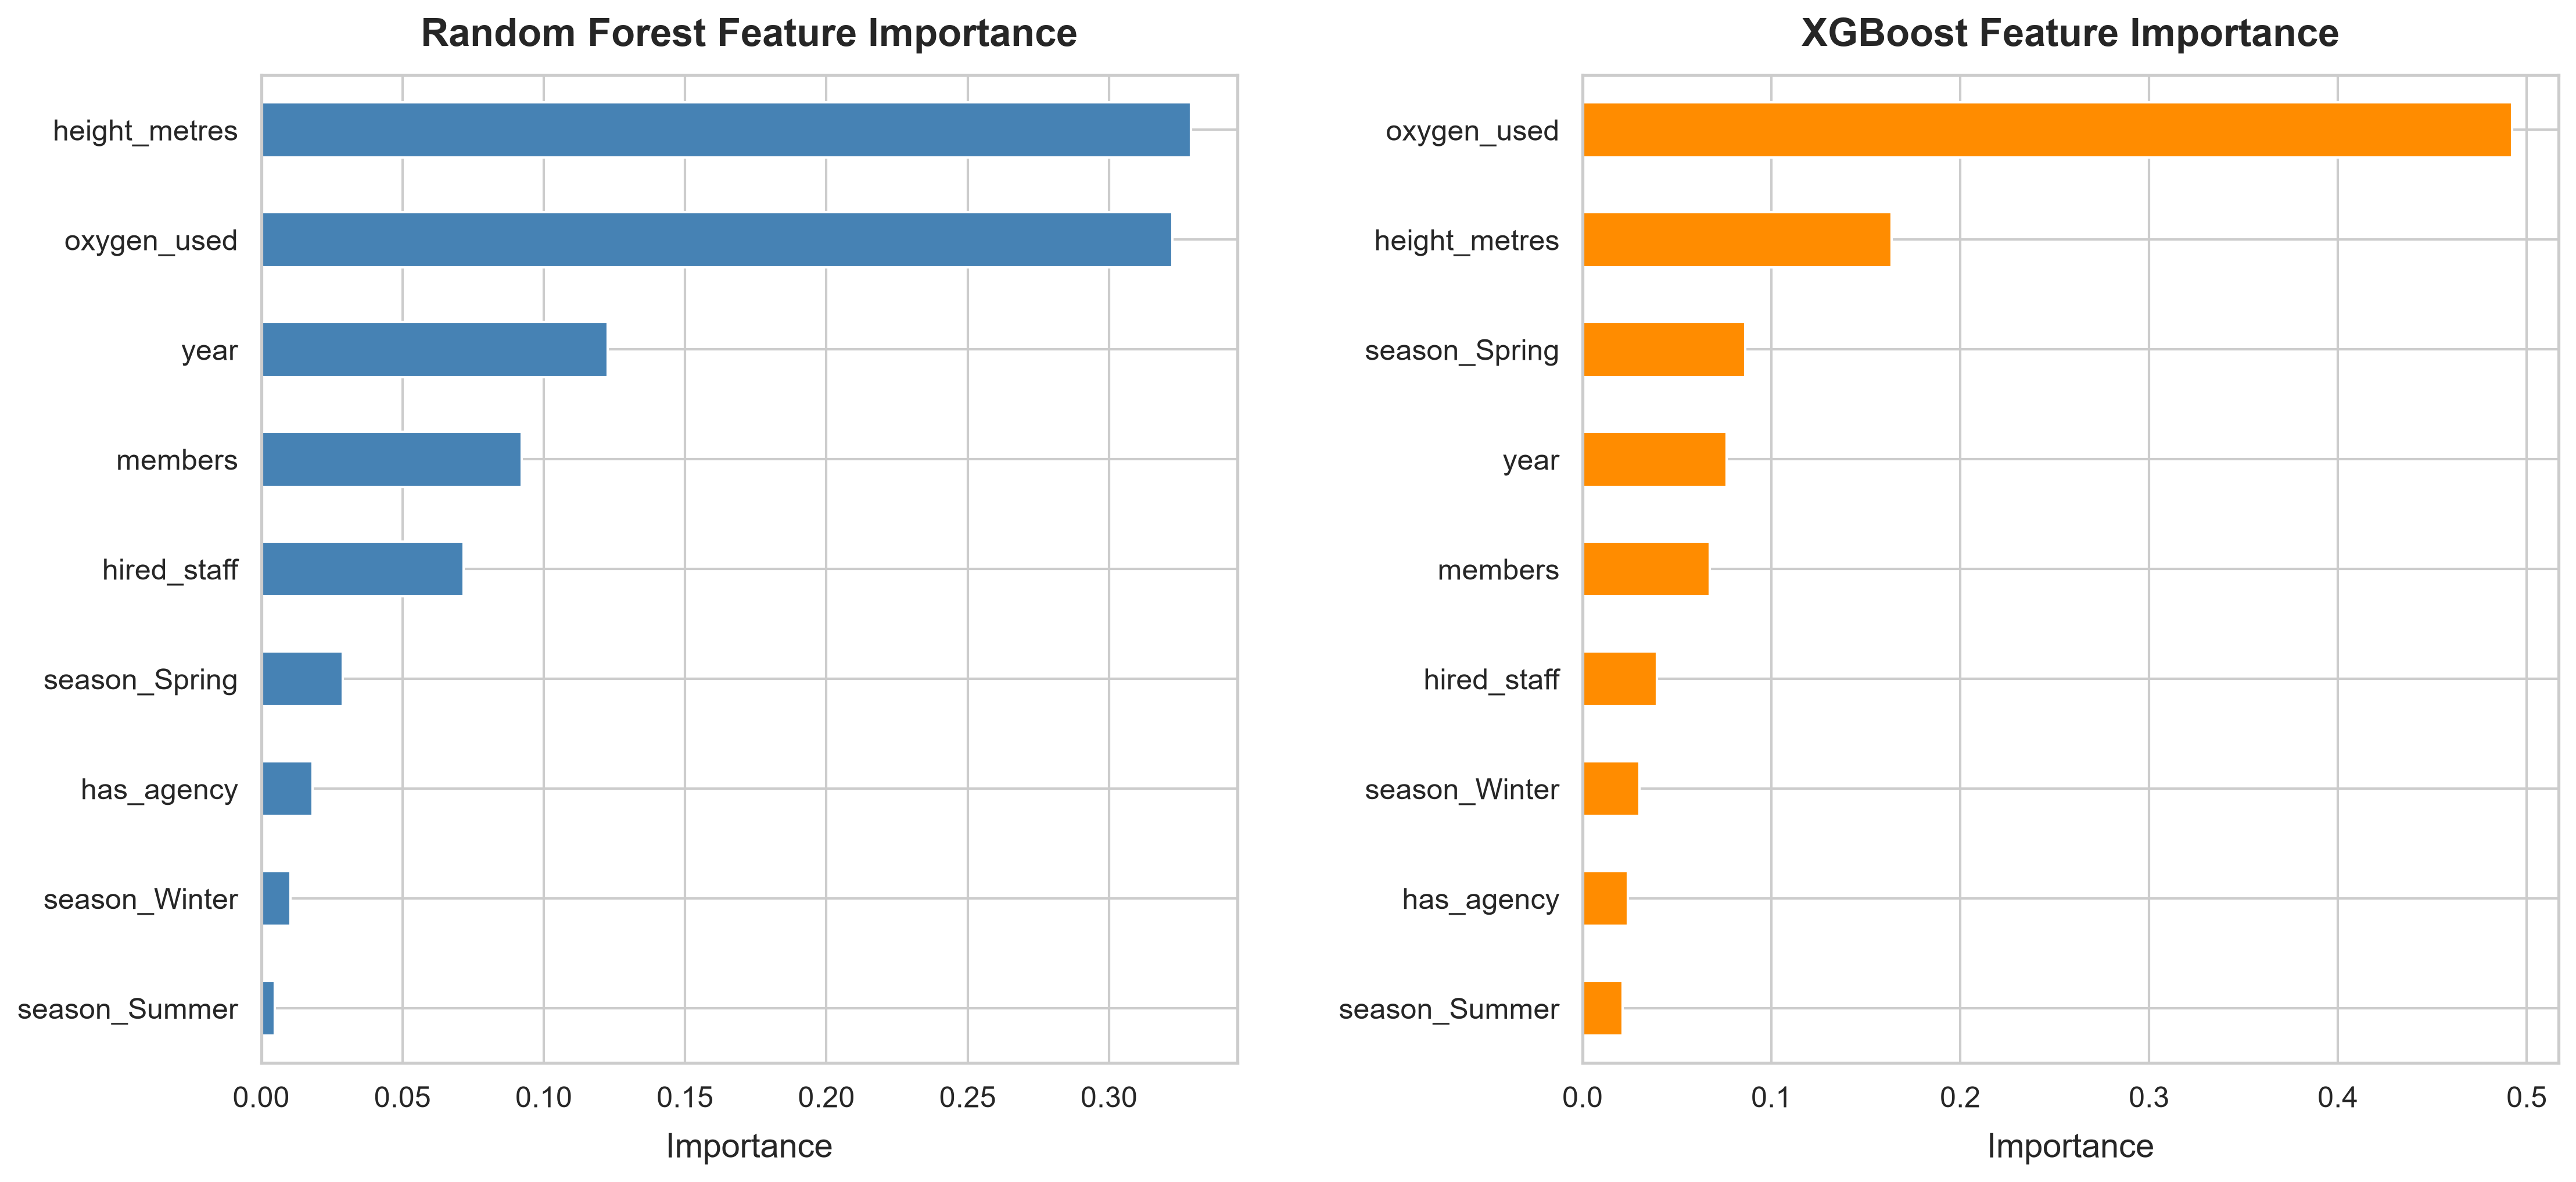

In [103]:
import matplotlib.pyplot as plt
import pandas as pd

rf_est = tuned_models["Random Forest"].best_estimator_
xgb_est = tuned_models["XGBoost"].best_estimator_

rf_importance = pd.Series(rf_est.feature_importances_, index=X_train.columns).sort_values()
xgb_importance = pd.Series(xgb_est.feature_importances_, index=X_train.columns).sort_values()

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

fig, ax = plt.subplots(1, 2, figsize=(15, 7), dpi=300)

rf_importance.plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("Random Forest Feature Importance", pad=12)
ax[0].set_xlabel("Importance", labelpad=8)

xgb_importance.plot(kind="barh", ax=ax[1], color="darkorange")
ax[1].set_title("XGBoost Feature Importance", pad=12)
ax[1].set_xlabel("Importance", labelpad=8)

plt.tight_layout(w_pad=3.0)
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [104]:
import pickle

chosen_model_name = "Random Forest"  # or "XGBoost"
chosen_threshold = 0.75

best_estimator = tuned_models[chosen_model_name].best_estimator_
best_params = tuned_models[chosen_model_name].best_params_

print("Selected model:", chosen_model_name)
print("Best parameters:", best_params)
print("Chosen threshold:", chosen_threshold)

artifact = {
    "model_name": chosen_model_name,
    "model": best_estimator,
    "best_params": best_params,
    "threshold": chosen_threshold,
    "feature_names": list(X_train.columns),
}

filename = f"{chosen_model_name.lower().replace(' ', '_')}_t{str(chosen_threshold).replace('.', '')}.pkl"

with open(filename, "wb") as f:
    pickle.dump(artifact, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Saved model bundle to: {filename}")

Selected model: Random Forest
Best parameters: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 200}
Chosen threshold: 0.75
Saved model bundle to: random_forest_t075.pkl


In [105]:
import pickle
import numpy as np
import pandas as pd

filename = "random_forest_t075.pkl"  # match your saved filename

with open(filename, "rb") as f:
    artifact = pickle.load(f)

loaded_model = artifact["model"]
threshold = artifact["threshold"]
feature_names = artifact["feature_names"]

# Ensure columns match training order
X_new = X_test[feature_names]

# Predicted probabilities for class 1 (expedition success)
y_prob = loaded_model.predict_proba(X_new)[:, 1]

# Custom-threshold binary predictions
y_pred = (y_prob >= threshold).astype(int)

results = pd.DataFrame({
    "success_probability": np.round(y_prob, 4),
    "predicted_class": y_pred,
})
display(results.head())

,success_probability,predicted_class
0,0.5050,0
1,0.4929,0
2,0.4929,0
3,0.5039,0
4,0.5039,0
